# Capitolo 16 — Affidabilita e valutazione
 **Arcangelo Distante e Cosimo Distante**

 Questo laboratorio verifica metodi con array analitici o dati sintetici. Non usa immagini esterne, pesi preaddestrati o download di dataset. Le attività aperte **N16.A1–N16.A3** chiedono di distinguere ciò che il calcolo dimostra dai limiti dell’esempio.

 ## Avvio e salvataggio
 In Google Colab, aprire il notebook dal repository GitHub attraverso **File → Apri notebook → GitHub**, oppure caricare questo file. Scegliere un runtime CPU: NumPy e Matplotlib sono sufficienti. Eseguire le celle dall’alto verso il basso; per ripartire, riavviare il runtime e rieseguire tutto. In locale usare Jupyter con Python 3, NumPy e Matplotlib. Nessun altro materiale deve essere caricato.

 I risultati sono salvati in `output_capitolo16` nella cartella di lavoro. Al termine scaricare la cartella degli output e salvare una copia del notebook eseguito. In Colab i file del runtime sono temporanei. Un’esecuzione locale non documenta automaticamente una prova svolta nel servizio Colab.


In [1]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=6, suppress=True)
OUTPUT = Path("output_capitolo16")
OUTPUT.mkdir(exist_ok=True)
risultati = {"capitolo": 16, "natura": "esempi analitici e sintetici", "dispositivo": "CPU"}
def mostra(a):
    return np.array2string(np.asarray(a), precision=6, separator=", ")


## N16.A1 — Il gruppo nascosto nella media
I conteggi sono assegnati: A contiene 90 casi, 86 corretti; B 10 casi, 4 corretti. **Domande:** quanto valgono accuracy aggregata, media dei gruppi e peggiore gruppo? Che cosa cambia con un mix futuro 50%–50%, a prestazioni per gruppo ipotizzate costanti? Questa ipotesi prova che il sistema resterà stabile su una nuova camera?


In [2]:
n=np.array([90,10]);corretti=np.array([86,4]);per_gruppo=corretti/n
aggregata=float(corretti.sum()/n.sum());macro=float(per_gruppo.mean());worst=float(per_gruppo.min())
print("Accuracy gruppi:",mostra(per_gruppo),"aggregata:",aggregata,"media gruppi:",macro,"peggiore:",worst)
risultati["gruppi"]={"numerosita":n.tolist(),"corretti":corretti.tolist(),"accuracy":per_gruppo.tolist(),"aggregata":aggregata,"media_gruppi":macro,"worst_group":worst,"mix_meta_meta":macro}
np.savetxt(OUTPUT/"gruppi.csv",np.column_stack([n,corretti,per_gruppo]),delimiter=",",header="numero,corretti,accuracy",comments="")


Accuracy gruppi: [0.955556, 0.4     ] aggregata: 0.9 media gruppi: 0.6777777777777778 peggiore: 0.4


## N16.A2 — Stessa accuracy, probabilità diverse
Riproduciamo i dieci casi binari del testo: sei corretti e quattro errati. A ha confidenza costante 0.9, B 0.6. Brier somma i due termini delle classi. **Domande:** quali NLL, Brier ed ECE si ottengono mettendo tutti i casi in un unico bin? Perché una probabilità vera 0.1 pesa tanto nella NLL? Che cosa conserva una temperatura positiva applicata agli score, e che cosa non garantisce sotto domain shift?


In [3]:
y=np.zeros(10,dtype=int);pred=np.array([0]*6+[1]*4)
def metrics(confidence):
    probs=np.full((10,2),1-confidence)
    probs[np.arange(10),pred]=confidence
    true=probs[np.arange(10),y];onehot=np.eye(2)[y]
    return {"accuracy":float(np.mean(pred==y)),"nll":float(-np.log(true).mean()),"brier":float(np.sum((probs-onehot)**2,axis=1).mean()),"ece_un_bin":float(abs(np.mean(pred==y)-confidence))}
A=metrics(.9);B=metrics(.6)
s=np.array([np.log(4.),0.]);temp={}
for T in (.5,1.,2.):
    p=np.exp(s/T-np.max(s/T));p/=p.sum();temp[str(T)]=p.tolist()
print("Modello A:",A,"Modello B:",B,"Temperature:",temp,sep="\n")
assert np.allclose(temp["2.0"],[2/3,1/3])
risultati["qualita_probabilistica"]={"A":A,"B":B,"temperatura":temp,"limite":"Numeri assegnati; il confronto non prova robustezza fuori distribuzione."}


Modello A:
{'accuracy': 0.6, 'nll': 0.984250346592314, 'brier': 0.66, 'ece_un_bin': 0.30000000000000004}
Modello B:
{'accuracy': 0.6, 'nll': 0.6730116670092564, 'brier': 0.48, 'ece_un_bin': 0.0}
Temperature:
{'0.5': [0.9411764705882353, 0.058823529411764705], '1.0': [0.8, 0.2], '2.0': [0.6666666666666666, 0.3333333333333333]}


## N16.A3 — Rischio, copertura e insiemi conformi
Usiamo gli otto errori assegnati nel testo. L’ultimo calcolo illustra il quantile split-conformal per nove score, senza sostenere una garanzia su un dataset costruito a mano. **Domande:** perché il rischio empirico può scendere aggiungendo un caso? Quale lavoro resta per gli esempi rifiutati? Quali ipotesi consentirebbero una garanzia conforme e perché uno shift arbitrario può invalidarla?


Punti operativi: [{'soglia': 0.9, 'copertura': 0.375, 'rischio': 0.0}, {'soglia': 0.8, 'copertura': 0.625, 'rischio': 0.2}, {'soglia': 0.6, 'copertura': 1.0, 'rischio': 0.5}, {'soglia': 1.0, 'copertura': 0.0, 'rischio': None}]


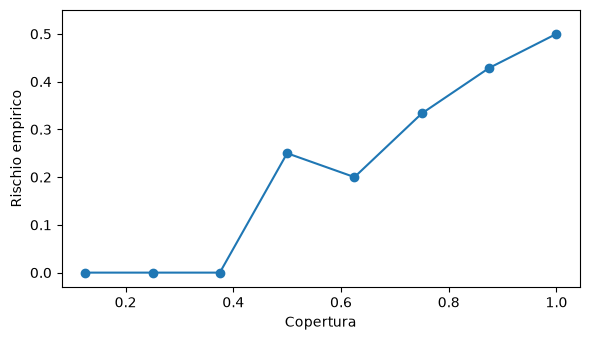

Conformal: k 8 q 0.8 insieme [0, 1]


In [4]:
conf=np.array([.99,.95,.90,.85,.80,.75,.70,.60]);err=np.array([0,0,0,1,0,1,1,1])
coverage=np.arange(1,9)/8;risk=np.cumsum(err)/np.arange(1,9)
rows=[]
for tau in (.9,.8,.6,1.):
    accept=conf>=tau;count=int(accept.sum());rows.append({"soglia":tau,"copertura":float(count/8),"rischio":float(err[accept].mean()) if count else None})
print("Punti operativi:",rows)
fig,ax=plt.subplots(figsize=(6,3.5));ax.plot(coverage,risk,"o-");ax.set(xlabel="Copertura",ylabel="Rischio empirico",ylim=(-.03,.55));fig.tight_layout();fig.savefig(OUTPUT/"rischio_copertura.png",dpi=160);plt.show()
scores=np.arange(1,10)/10;alpha=.2;n=len(scores);k=int(np.ceil((n+1)*(1-alpha)));q=float(np.sort(scores)[k-1]) if k<=n else float("inf")
p=np.array([.6,.3,.1]);set_indices=np.flatnonzero(1-p<=q)
print("Conformal: k",k,"q",q,"insieme",mostra(set_indices))
risultati["astensione"]={"punti":rows,"copertura":coverage.tolist(),"rischio":risk.tolist()}
risultati["conforme"]={"n":n,"alpha":alpha,"k":k,"q":q,"probabilita":p.tolist(),"insieme":set_indices.tolist(),"limite":"La garanzia marginale richiede scambiabilità fra calibrazione e nuovo esempio, modello e score fissati prima della calibrazione."}
np.savetxt(OUTPUT/"rischio_copertura.csv",np.column_stack([coverage,risk]),delimiter=",",header="copertura,rischio",comments="")


In [5]:
with (OUTPUT / "risultati_capitolo16.json").open("w", encoding="utf-8") as f:
    json.dump(risultati, f, indent=2, ensure_ascii=False, allow_nan=False)
print("Risultati salvati in", OUTPUT)


Risultati salvati in output_capitolo16
